Mean = 7.376498599999997
Std = 0.25545509532878763
1% value quantile = 6.745000000000001
5% value quantile = 6.978999999999999
99% Credit VaR relative to mean = 0.631498599999996


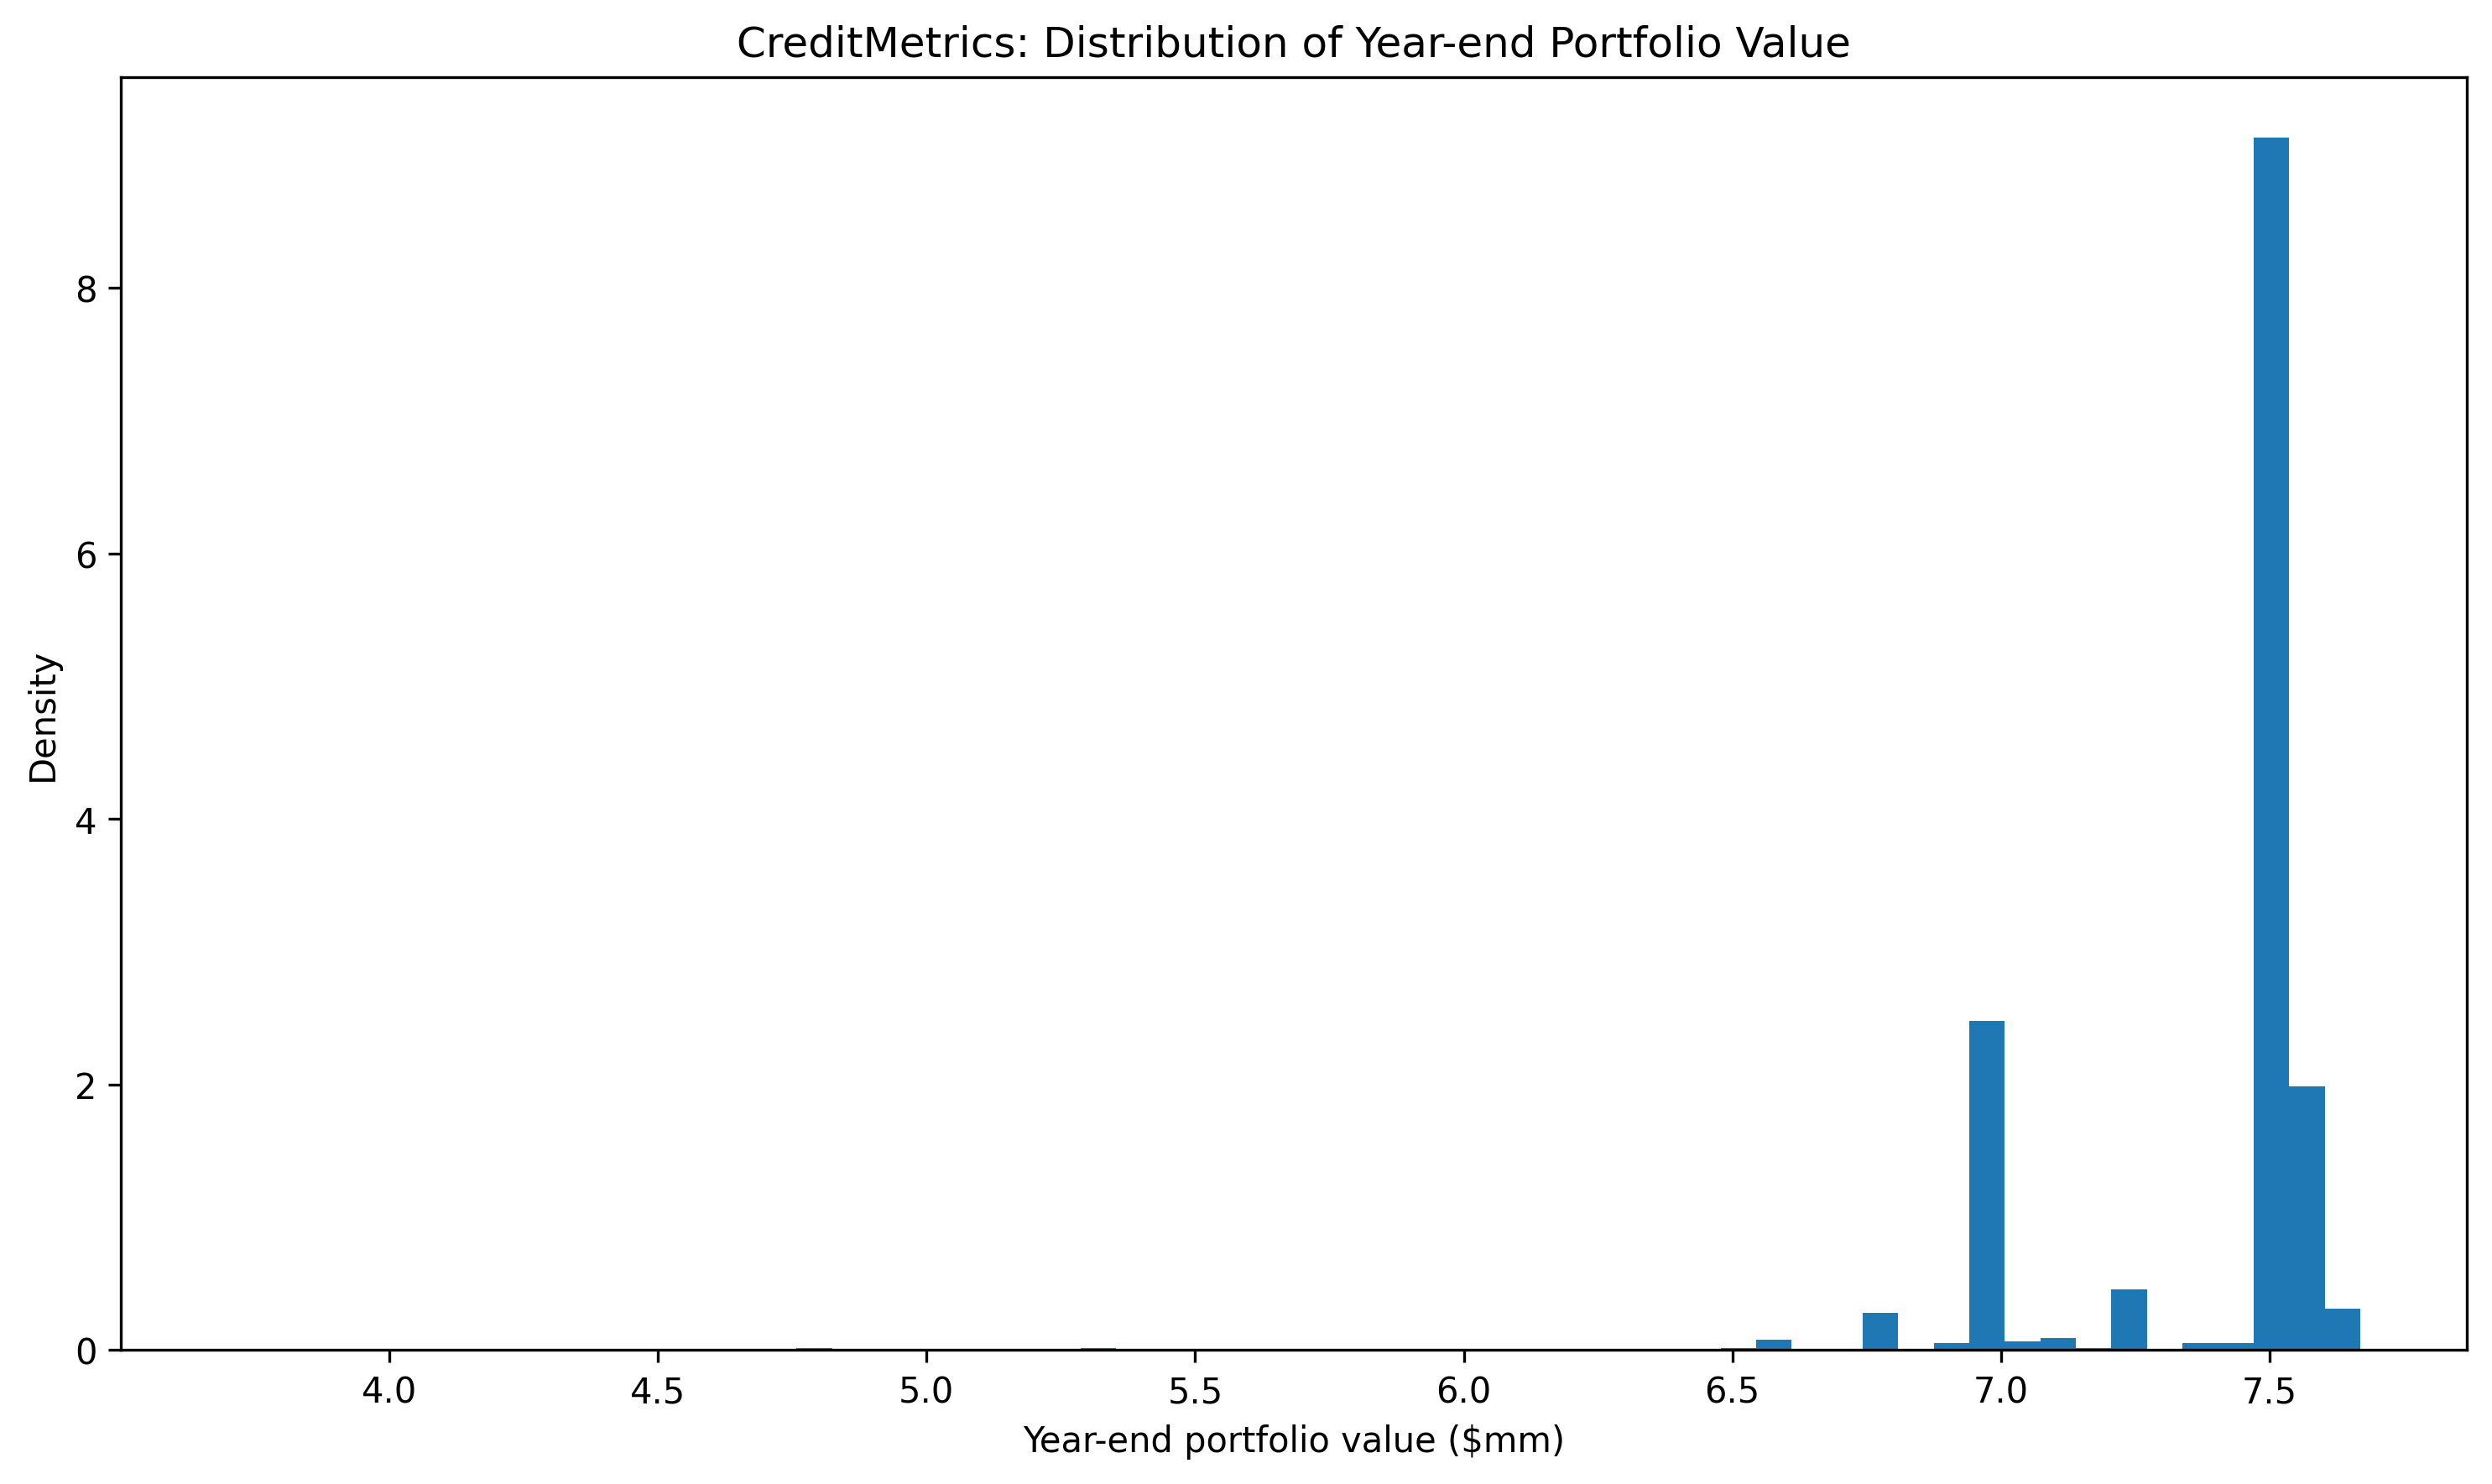

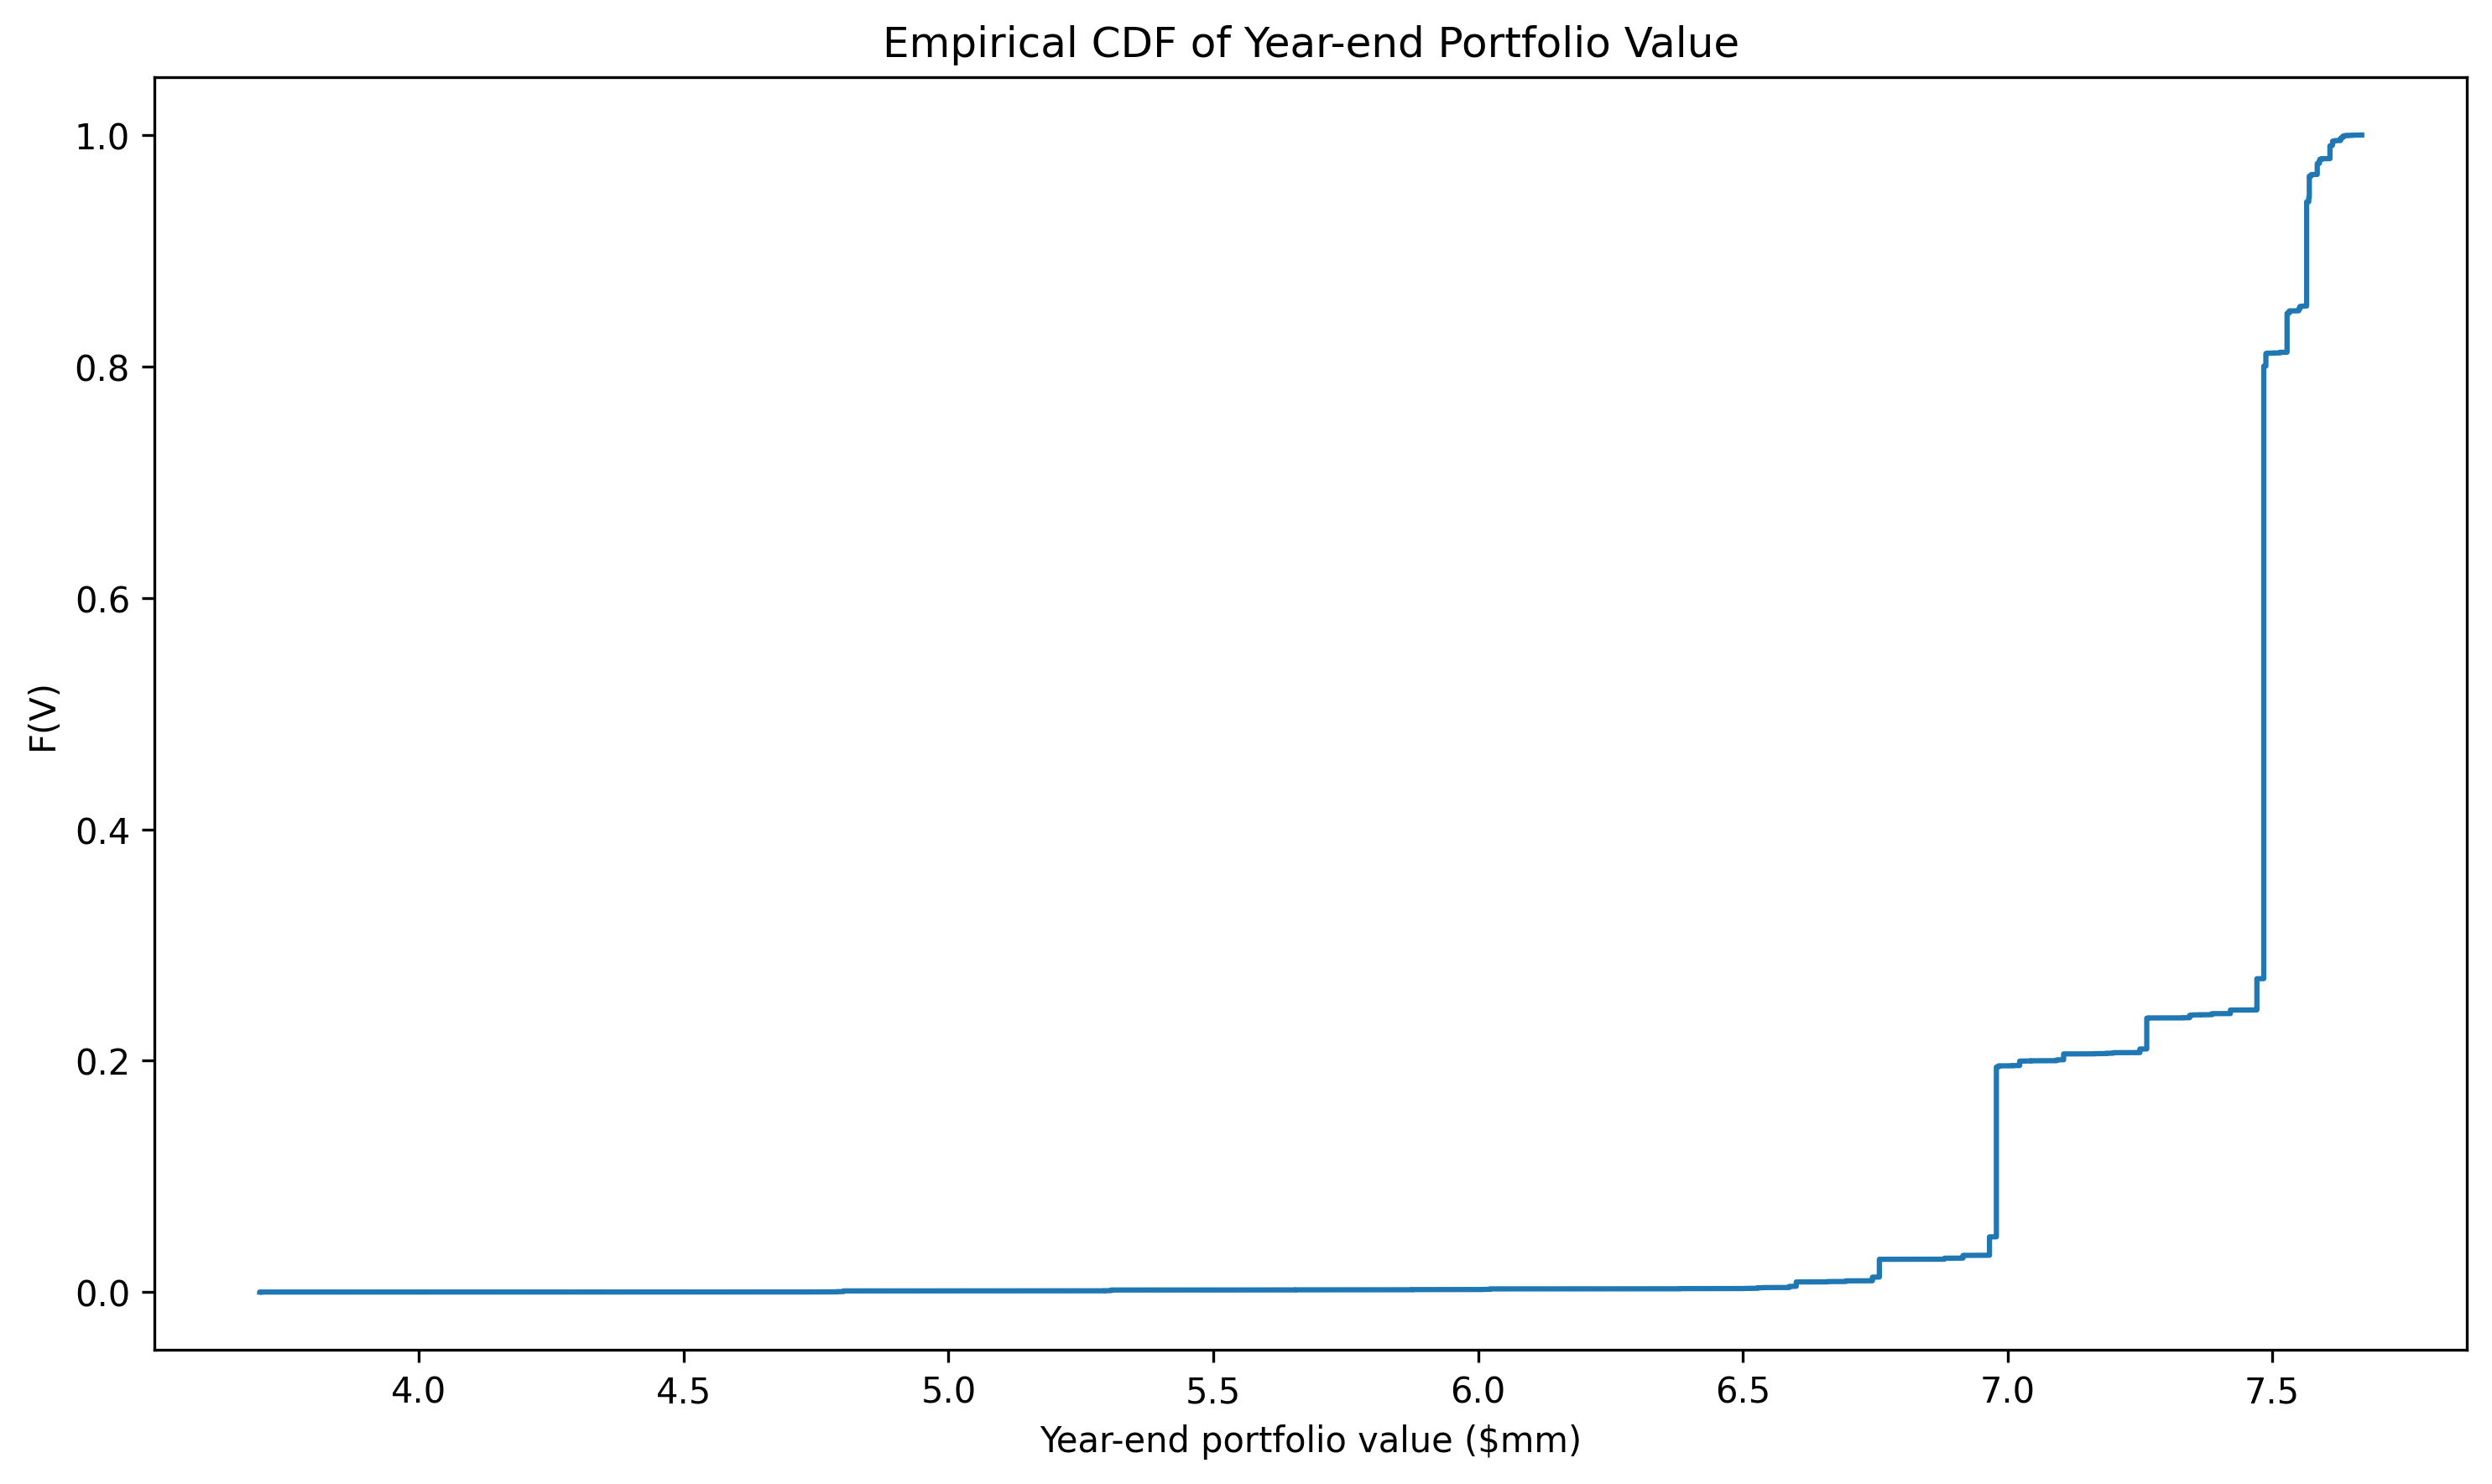

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

plt.rcParams['figure.dpi'] = 300
plt.rcParams['font.serif'] = ['Times New Roman']

# ============================================================
# 1. Ratings
# ============================================================

ratings = np.array([
    "AAA", "AA", "A", "BBB",
    "BB", "B", "CCC", "Default"
])


# ============================================================
# 2. One-year transition probabilities
# ============================================================

# Firm 1: initially BBB
p1 = np.array([
    0.02, 0.33, 5.95, 86.93,
    5.30, 1.17, 0.12, 0.18
]) / 100

# Firm 2: initially A
p2 = np.array([
    0.09, 2.27, 91.05, 5.52,
    0.74, 0.26, 0.01, 0.06
]) / 100

# Firm 3: initially CCC
p3 = np.array([
    0.22, 0.00, 0.22, 1.30,
    2.38, 11.24, 64.86, 19.79
]) / 100

# 表格因四舍五入合计为 100.01%，归一化处理
p3 = p3 / p3.sum()


# ============================================================
# 3. Year-end bond values ($mm)
# ============================================================

v1 = np.array([
    4.375, 4.368, 4.346, 4.302,
    4.081, 3.924, 3.346, 2.125
])

v2 = np.array([
    2.132, 2.130, 2.126, 2.113,
    2.063, 2.028, 1.774, 1.023
])

v3 = np.array([
    1.162, 1.161, 1.161, 1.157,
    1.142, 1.137, 1.056, 0.551
])


# ============================================================
# 4. Construct rating thresholds
# ============================================================

def get_thresholds(p_best_to_worst):

    # 信用状态从差到好：
    # Default, CCC, B, BB, BBB, A, AA, AAA
    p_worst_to_best = p_best_to_worst[::-1]

    cumulative_prob = np.cumsum(
        p_worst_to_best
    )

    # 7个threshold划分8个评级状态
    thresholds = norm.ppf(
        cumulative_prob[:-1]
    )

    return thresholds


threshold1 = get_thresholds(p1)
threshold2 = get_thresholds(p2)
threshold3 = get_thresholds(p3)


# ============================================================
# 5. Gaussian CreditMetrics dependence
# ============================================================

rho = 0.30

Sigma = np.array([
    [1.0, rho, rho],
    [rho, 1.0, rho],
    [rho, rho, 1.0]
])


# ============================================================
# 6. Monte Carlo
# ============================================================

N = 10_000_000

rng = np.random.default_rng(12345)

Z = rng.multivariate_normal(
    mean=[0, 0, 0],
    cov=Sigma,
    size=N
)


# ============================================================
# 7. Convert latent variables into ratings
# ============================================================

def latent_to_rating_index(z, threshold):

    # digitize得到：
    # 0 = Default
    # 1 = CCC
    # ...
    # 7 = AAA

    idx_worst_to_best = np.digitize(
        z,
        threshold,
        right=True
    )

    # 转换为：
    # 0 = AAA
    # ...
    # 7 = Default

    idx_best_to_worst = (
        7 - idx_worst_to_best
    )

    return idx_best_to_worst


idx1 = latent_to_rating_index(
    Z[:, 0], threshold1
)

idx2 = latent_to_rating_index(
    Z[:, 1], threshold2
)

idx3 = latent_to_rating_index(
    Z[:, 2], threshold3
)


# ============================================================
# 8. Portfolio year-end value
# ============================================================

V1 = v1[idx1]
V2 = v2[idx2]
V3 = v3[idx3]

Vp = V1 + V2 + V3


# ============================================================
# 9. Summary
# ============================================================

mean_V = np.mean(Vp)
std_V = np.std(Vp)

q01 = np.quantile(Vp, 0.01)
q05 = np.quantile(Vp, 0.05)

credit_var_99 = mean_V - q01

print("Mean =", mean_V)
print("Std =", std_V)

print("1% value quantile =", q01)
print("5% value quantile =", q05)

print(
    "99% Credit VaR relative to mean =",
    credit_var_99
)


# ============================================================
# 10. Empirical distribution function
# ============================================================

x_sorted = np.sort(Vp)

F_empirical = (
    np.arange(1, N + 1) / N
)


# ============================================================
# 11. Histogram
# ============================================================

plt.figure(figsize=(10, 6), dpi=300)

plt.hist(
    Vp,
    bins=60,
    density=True
)

plt.xlabel(
    "Year-end portfolio value ($mm)"
)

plt.ylabel("Density")

plt.title(
    "CreditMetrics: "
    "Distribution of Year-end Portfolio Value"
)

plt.tight_layout()
plt.show()


# ============================================================
# 12. Empirical CDF
# ============================================================

plt.figure(figsize=(10, 6), dpi=300)

plt.plot(
    x_sorted,
    F_empirical
)

plt.xlabel(
    "Year-end portfolio value ($mm)"
)

plt.ylabel("F(V)")

plt.title(
    "Empirical CDF of "
    "Year-end Portfolio Value"
)

plt.tight_layout()
plt.show()